# Partie II : système pseudo-autonome
On garde tout le réseau de la Partie I (CPG, 8 neurones par patte, interneurones de direction, compteurs de virage).
On remplace seulement les commandes fixées à la main (`mode_G`, `mode_D`, `virage_G`, `virage_D`, `I_drive`) par des **neurones de commande** pilotés par des **neurones sensoriels**.

```
Stimuli (contact + intensité) : flanc G · flanc D · avant · arrière
        │
Neurones sensoriels SENS_G/D/AV/AR (M neurones, seuils différents)  ── sélection d'action (inhibition rapide)
        │  synapses lentes (tau_persist)
Neurones de commande CMD_AV_G · CMD_AR_G · CMD_AV_D · CMD_AR_D · COMPTEUR_G/D · drive du CPG
        │
Réseau de la Partie I : CPG → interneurones de direction → motoneurones des pattes
```

**Interprétation :** une patte ne bouge que d'avant en arrière, l'hexapode ne peut pas faire de pas de côté. « Déplacement à gauche » veut donc dire **tourner vers la gauche**.

### Imports

In [1]:
import numpy as np
from brian2 import *
import matplotlib.pyplot as plt

prefs.codegen.target = 'numpy'
BrianLogger.log_level_error()   # masque les avertissements 'tau' deja vus en Partie I

### Modèle et paramètres
Même modèle LIF qu'en Partie I, avec deux ajouts :
- `gs` : **courant synaptique lent** (signé) qui décroît avec `tau_s`. Une synapse lente fait `gs += w` (excitatrice) ou `gs -= w` (inhibitrice). C'est le mécanisme de **persistance** : un contact de 100 ms produit une réaction qui dure ~`tau_persist`.
- `seuil` : seuil de décharge propre à chaque neurone (1 partout, sauf chez les capteurs où il varie → recrutement).

$$\tau \frac{dv}{dt} = I + I_b + g_s - v - a - g_i, \qquad \text{décharge si } v > \text{seuil}$$

**Biais de mode (CMD → interneurones).** En Partie I, le biais `B_ET = 0.6` des interneurones (IN) était fixé à la main. Maintenant, chaque décharge du neurone de commande ajoute du courant lent sur les IN de son côté, avec une synapse **saturante** (`gs += W_MODE (G_MODE - gs)`, $\tau$ = 50 ms) : le biais reste entre ~0.45 et 0.85 quelle que soit la fréquence de CMD (50 à 300 Hz). Il faut > 0.4 pour que le ET (CPG + biais) franchisse le seuil, et < 1 pour que l'IN ne décharge pas seul.

**Compteur.** En Partie I, le compteur était un intégrateur parfait (fuite 100 s) qui recevait le CPG seulement quand le virage était activé. Ici il reçoit **toujours** les salves de A, mais il fuit ($\tau$ = 150 ms) : seules, les salves du CPG ne suffisent jamais à atteindre le seuil (pic ≈ 0.5 au repos). Le courant sensoriel lent s'ajoute et le compteur décharge une salve sur n, avec n qui diminue quand le contact est fort.

In [2]:
eqs = '''
dv/dt  = (I + Ib + gs - v - a - gi) / tau : 1 (unless refractory)
da/dt  = -a / tau_a                       : 1   # adaptation (CPG seulement)
dgi/dt = -gi / tau_i                      : 1   # inhibition synaptique rapide
dgs/dt = -gs / tau_s                      : 1   # courant synaptique lent (persistance)
I : 1                                           # I_drive (CPG) ou courant sensoriel k x intensite
Ib : 1                                          # biais tonique (CMD_AV)
seuil : 1 (constant)                            # seuil de decharge (varie chez les capteurs)
inc_a : 1 (constant)                            # saut d'adaptation par decharge
tau : second (constant)
tau_a : second (constant)
tau_i : second (constant)
tau_s : second (constant)
'''
# ---------------------------------------------------------------- Partie I (inchanges)
W_AB     = 4.0     # inhibition mutuelle A <-> B
W_MOT    = 1.5     # source -> LEVER/POSER, IN -> AVANT/ARRIERE (suffit seul)
W_ET     = 0.6     # CPG -> IN (insuffisant seul : principe du ET)
W_CONTRA = 3.0     # LEVER <-> POSER, AVANT <-> ARRIERE
W_INHIB  = 3.0     # INHIB_s -> IN du cote s
TAU_BLOC = 55*ms   # inhibition lente des IN : bloque ~ un cycle
DELAI    = 3*ms    # latence CPG -> pattes

# ---------------------------------------------------------------- Partie II
PARAM = dict(
    M=10, K_SENS=2.0, SEUIL_MIN=0.2, SEUIL_MAX=1.8,   # capteurs : courant = K_SENS x intensite
    TAU_PERSIST=800*ms,                              # synapses lentes capteur -> commande
    DELAI_SENS=0*ms,                                 # latence capteur -> commande
    I_CMD=1.8,                                       # biais tonique de CMD_AV (~100 Hz)
    W_WTA=1.0,                                       # CMD_AV_s <-> CMD_AR_s
    W_MODE=0.5, G_MODE=0.9, TAU_MODE=50*ms,          # CMD -> IN (synapse saturante)
    W_AV_AR=0.05, W_AV_AV=0.04,                      # SENS_AV -> CMD_AR (+), CMD_AV (-)
    W_AV_CPT=0.0,                                    # option : SENS_AV -> COMPTEUR_G (recul en tournant)
    W_LAT_CPT=0.04,                                  # SENS_D -> COMPTEUR_G (et symetrique)
    W_LAT_AR=0.025,                                  # SENS_D -> CMD_AR_G, poids faible (pivot)
    W_AR_CPG=0.01,                                   # SENS_AR -> A et B du CPG
    W_CPT=0.35, TAU_CPT=150*ms,                      # CPG(A) -> COMPTEUR, fuite du compteur
    W_AR_CPT=3.0,                                    # CMD_AR_s -| COMPTEUR_s (le pivot remplace le virage)
    W_S_AV=2.0, W_S_LAT=2.0, W_S_GD=1.0,             # selection d'action (inhibition rapide)
    HABITUATION=False, U_STD=0.05, TAU_REC=4*second, # bonus : depression SENS_AR -> CPG
)


def pop(n, tau=2*ms, tau_i=10*ms, tau_a=1*second, tau_s=50*ms, inc_a=0, Ib=0, I=0, seuil=1):
    '''Population LIF au modele commun.'''
    G = NeuronGroup(n, eqs, threshold='v > seuil', reset='v = 0; a += inc_a',
                    refractory=2*ms, method='euler')
    G.tau, G.tau_i, G.tau_a, G.tau_s = tau, tau_i, tau_a, tau_s
    G.inc_a, G.Ib, G.I, G.seuil = inc_a, Ib, I, seuil
    return G


def syn(src, tgt, w, i=None, j=None, inhib=False, lente=False, delay=0*ms, on_pre=None, model=''):
    '''Rapide : excitatrice (v += w) ou inhibitrice (gi += w). Lente : gs += w ou gs -= w.
    i = j = None : connexion tout-a-tout.'''
    if on_pre is None:
        var = 'gs_post' if lente else ('gi_post' if inhib else 'v_post')
        on_pre = f"{var} {'-' if lente and inhib else '+'}= {w}"
    S = Synapses(src, tgt, model=model, on_pre=on_pre)
    if i is None: S.connect()
    else: S.connect(i=np.asarray(i), j=np.asarray(j))
    S.delay = delay
    return S

### Construction du réseau
- Partie I : identique (patte `i = 2k + s`, groupe `(k + s) % 2`).
- 4 populations sensorielles `SENS_G, SENS_D, SENS_AV, SENS_AR` de M neurones, seuils de `SEUIL_MIN` à `SEUIL_MAX`.
- 4 neurones de commande, indice `2s + ar` : `0 = CMD_AV_G, 1 = CMD_AR_G, 2 = CMD_AV_D, 3 = CMD_AR_D`. CMD_AV a un biais tonique → marche avant par défaut.
- Les commandes sont **par côté** et se connectent à toutes les pattes du côté avec la même règle d'indices qu'en Partie I : on change toujours seulement `N_PAIRES`.

Un stimulus est un tuple `(capteur, t0, intensité, durée)`. `pattes=False` construit seulement capteurs + commandes + CPG + compteurs (plus rapide, pour les études paramétriques qui ne regardent que les commandes).

In [3]:
NOMS = ['LEVER', 'POSER', 'AVANT', 'ARRIERE', 'IN_sw_av', 'IN_st_ar', 'IN_sw_ar', 'IN_st_av']
CAPTEURS = ['G', 'D', 'AV', 'AR']
CMD_NOMS = ['CMD_AV_G', 'CMD_AR_G', 'CMD_AV_D', 'CMD_AR_D']


def simuler(stimuli=(), N_PAIRES=3, I_drive=2.0, duree=2*second, delta=0*ms, pattes=True, extra=None, **p):
    """stimuli : liste de (capteur, t0, intensite, duree), ou None si le courant sensoriel est
    impose de l'exterieur (boucle fermee). p : remplace des valeurs de PARAM."""
    P_ = PARAM | p
    start_scope()
    M = P_['M']
    tous = lambda cibles: tuple(x.ravel() for x in np.meshgrid(range(M), cibles))
    n = 2 * N_PAIRES                          # patte i = 2k + s
    k, s = np.arange(n) // 2, np.arange(n) % 2
    grp = (k + s) % 2                         # tripode / alternance
    sw, st = grp, 1 - grp                     # source swing / stance (0 = A, 1 = B)
    d = DELAI + k * delta                     # onde metachronale (option)

    # ------------------------------------------------ Partie I : CPG, compteurs, INHIB
    cpg = pop(2, tau=10*ms, tau_i=20*ms, tau_a=200*ms, inc_a=1.5, I=I_drive, tau_s=P_['TAU_PERSIST'])
    cpg.v, cpg.a = [0.5, 0], [0, 1]           # B part adapte -> demarre en antiphase
    cpt = pop(2, tau=P_['TAU_CPT'], tau_s=P_['TAU_PERSIST'])   # COMPTEUR_G, COMPTEUR_D (fuyants)
    inh = pop(2)                              # INHIB_G, INHIB_D
    S = [syn(cpg, cpg, W_AB, [0, 1], [1, 0], inhib=True),
         syn(cpg, cpt, P_['W_CPT'], [0, 0], [0, 1]),          # chaque salve de A -> compteurs
         syn(cpt, inh, W_MOT, [0, 1], [0, 1])]

    # ------------------------------------------------ Partie II : capteurs et commandes
    if stimuli is not None:                   # stimuli scriptes -> courant k x intensite
        stim = np.zeros((int(duree / ms) + 1, 4))
        for cap, t0, inten, dur in stimuli:
            stim[int(t0 / ms):int((t0 + dur) / ms), CAPTEURS.index(cap)] = inten
        stim_ta = TimedArray(stim, dt=1*ms)
    SENS = {}
    for c, cap in enumerate(CAPTEURS):
        SENS[cap] = pop(M, tau=10*ms, seuil=np.linspace(P_['SEUIL_MIN'], P_['SEUIL_MAX'], M))
        if stimuli is not None:
            SENS[cap].run_regularly(f"I = {P_['K_SENS']} * stim_ta(t, {c})", dt=1*ms)
    cmd = pop(4, tau=10*ms, tau_s=P_['TAU_PERSIST'], Ib=[P_['I_CMD'], 0, P_['I_CMD'], 0])

    ds = P_['DELAI_SENS']
    S += [syn(cmd, cmd, P_['W_WTA'], [0, 1, 2, 3], [1, 0, 3, 2], inhib=True),       # AV <-> AR
          syn(cmd, cpt, P_['W_AR_CPT'], [1, 3], [0, 1], inhib=True),                  # pivot > virage
          # recul : SENS_AV excite CMD_AR_G/D et inhibe CMD_AV_G/D (lentes)
          syn(SENS['AV'], cmd, P_['W_AV_AR'], *tous([1, 3]), lente=True, delay=ds),
          syn(SENS['AV'], cmd, P_['W_AV_AV'], *tous([0, 2]), lente=True, inhib=True, delay=ds),
          # virages : flanc D -> COMPTEUR_G (+ CMD_AR_G, poids faible) ; flanc G symetrique
          syn(SENS['D'], cpt, P_['W_LAT_CPT'], *tous([0]), lente=True, delay=ds),
          syn(SENS['G'], cpt, P_['W_LAT_CPT'], *tous([1]), lente=True, delay=ds),
          syn(SENS['D'], cmd, P_['W_LAT_AR'], *tous([1]), lente=True, delay=ds),
          syn(SENS['G'], cmd, P_['W_LAT_AR'], *tous([3]), lente=True, delay=ds)]
    if P_['W_AV_CPT'] > 0:
        S.append(syn(SENS['AV'], cpt, P_['W_AV_CPT'], *tous([0]), lente=True, delay=ds))
    # acceleration : SENS_AR -> A et B du CPG (lente), avec habituation en option
    if P_['HABITUATION']:
        S.append(syn(SENS['AR'], cpg, None, *tous([0, 1]), delay=ds,
                     model=f"dx/dt = (1 - x) / ({P_['TAU_REC'] / ms} * ms) : 1 (event-driven)",
                     on_pre=f"gs_post += {P_['W_AR_CPG']} * x; x -= {P_['U_STD']} * x"))
        S[-1].x = 1
    else:
        S.append(syn(SENS['AR'], cpg, P_['W_AR_CPG'], *tous([0, 1]), lente=True, delay=ds))
    # selection d'action : AVANT > FLANCS > ARRIERE (inhibition rapide entre capteurs)
    S += [syn(SENS['AV'], SENS[c], P_['W_S_AV'], inhib=True) for c in ['G', 'D', 'AR']]
    S += [syn(SENS[c], SENS['AR'], P_['W_S_LAT'], inhib=True) for c in ['G', 'D']]
    S += [syn(SENS['G'], SENS['D'], P_['W_S_GD'], inhib=True), syn(SENS['D'], SENS['G'], P_['W_S_GD'], inhib=True)]

    groupes = [cpg, cpt, inh, cmd, *SENS.values()]
    Mon = {'CPG': SpikeMonitor(cpg), 'CPT': SpikeMonitor(cpt), 'INH': SpikeMonitor(inh), 'CMD': SpikeMonitor(cmd)}
    Mon |= {'S_' + c: SpikeMonitor(SENS[c]) for c in CAPTEURS}
    gsM = [StateMonitor(g, 'gs', record=True, dt=1*ms) for g in (cmd, cpt, cpg)]

    # ------------------------------------------------ Partie I : pattes (inchange)
    if pattes:
        P = {nom: pop(n, tau_i=TAU_BLOC if nom.startswith('IN') else 10*ms) for nom in NOMS}
        for nom in ['IN_sw_av', 'IN_st_ar']: P[nom].gs = 0.7   # depart en regime de marche avant
        for nom, src in [('LEVER', sw), ('POSER', st)]:
            S.append(syn(cpg, P[nom], W_MOT, src, range(n), delay=d))
        for nom, src in [('IN_sw_av', sw), ('IN_sw_ar', sw), ('IN_st_av', st), ('IN_st_ar', st)]:
            S.append(syn(cpg, P[nom], W_ET, src, range(n), delay=d))
        for a_, b_ in [('IN_sw_av', 'AVANT'), ('IN_st_av', 'AVANT'), ('IN_sw_ar', 'ARRIERE'), ('IN_st_ar', 'ARRIERE')]:
            S.append(syn(P[a_], P[b_], W_MOT, range(n), range(n)))
        for a_, b_ in [('LEVER', 'POSER'), ('POSER', 'LEVER'), ('AVANT', 'ARRIERE'), ('ARRIERE', 'AVANT')]:
            S.append(syn(P[a_], P[b_], W_CONTRA, range(n), range(n), inhib=True))
        for nom in NOMS[4:]:
            S.append(syn(inh, P[nom], W_INHIB, s, range(n), inhib=True, delay=k * delta))
        # NOUVEAU : le biais de mode vient des neurones de commande (remplace mode_G / mode_D)
        for nom, ar in [('IN_sw_av', 0), ('IN_st_ar', 0), ('IN_sw_ar', 1), ('IN_st_av', 1)]:
            S.append(syn(cmd, P[nom], None, 2 * s + ar, range(n), delay=k * delta,
                         on_pre=f"gs_post += {P_['W_MODE']} * ({P_['G_MODE']} - gs_post)"))
        groupes += list(P.values())
        Mon |= {nom: SpikeMonitor(P[nom]) for nom in NOMS}

    objets = extra(Mon | {'n': n, 'SENS': SENS}) if extra else []
    Network(*groupes, *S, *Mon.values(), *gsM, *objets).run(duree)
    R = {nom: (m.t / ms, np.array(m.i)) for nom, m in Mon.items()}
    R |= {'t_gs': gsM[0].t / ms, 'gs_CMD': gsM[0].gs.copy(), 'gs_CPT': gsM[1].gs.copy(), 'gs_CPG': gsM[2].gs.copy()}
    return R | {'n': n, 'duree': duree / ms, 'M': M, 'pattes': pattes}

### Décodage des décharges en mouvement (Partie I)
Même règle qu'en Partie I, écrite sous forme d'objet pour pouvoir aussi la faire tourner **en ligne** (boucle fermée, section 9).

In [4]:
class Decodeur:
    """Contact (POSER/LEVER), position (AVANT/ARRIERE), poussees -> trajectoire (x, y, theta)."""
    def __init__(self, n, d=0.2, L=1.0, x=0.0, y=0.0, th=0.0, limites=None):
        self.n, self.d, self.L, self.limites = n, d, L, limites   # limites : (xmin, xmax, ymin, ymax)
        self.sol, self.pos = np.zeros(n, bool), np.zeros(n, int)  # pos : +1 avant, -1 arriere
        self.x, self.y, self.th = x, y, th
        self.traj, self.contact = [(0, x, y, th)], [[] for _ in range(n)]

    def evenement(self, t, i, c):
        if c == 'POSER' and not self.sol[i]: self.sol[i] = True; self.contact[i].append([t, None])
        elif c == 'LEVER' and self.sol[i]: self.sol[i] = False; self.contact[i][-1][1] = t
        elif c in ('AVANT', 'ARRIERE'):
            new = 1 if c == 'AVANT' else -1
            if self.sol[i] and self.pos[i] == -new:                 # poussee au sol
                ds = self.d / (self.n // 2) * (-new)                # +d si avant -> arriere
                self.th += ds / self.L * (1 if i % 2 else -1)       # cote D -> +theta (gauche)
                self.x += ds / 2 * np.cos(self.th); self.y += ds / 2 * np.sin(self.th)
                if self.limites:                                     # un mur bloque le corps
                    x0, x1, y0, y1 = self.limites
                    self.x, self.y = np.clip(self.x, x0, x1), np.clip(self.y, y0, y1)
                self.traj.append((t, self.x, self.y, self.th))
            self.pos[i] = new


def decoder(R, d=0.2, L=1.0):
    ev = []
    for c in ['LEVER', 'POSER', 'AVANT', 'ARRIERE']:
        t, i = R[c]
        ev += [(tt, ii, c) for tt, ii in zip(t, i)]
    D = Decodeur(R['n'], d, L)
    for e in sorted(ev): D.evenement(*e)
    for c in D.contact:
        if c and c[-1][1] is None: c[-1][1] = R['duree']
    return np.array(D.traj), D.contact

### Outils d'affichage et de mesure
`afficher` trace le raster complet du scénario (capteurs → commandes → compteurs → CPG → pattes) avec la trajectoire à droite. Les bandes colorées marquent les stimuli.

In [5]:
COUL = dict(G='C0', D='C1', AV='C3', AR='C2')


def pos_a(traj, t):
    """Position (x, y) interpolee au temps t (ms)."""
    return np.interp(t, traj[:, 0], traj[:, 1]), np.interp(t, traj[:, 0], traj[:, 2])


def freq_pas(R):
    """Frequence de pas instantanee (Hz) a partir des salves de A du CPG."""
    t, i = R['CPG']
    ta = t[i == 0]
    return ta[1:], 1000 / np.diff(ta)


def activite(R, nom, idx, apres=0):
    """Temps des decharges du neurone idx de la population nom apres 'apres' ms."""
    t, i = R[nom]
    return t[(i == idx) & (t >= apres)]


def duree_active(R, nom, idx, apres=0):
    """Duree (ms) entre la premiere et la derniere decharge d'un neurone (0 s'il ne decharge pas)."""
    t = activite(R, nom, idx, apres)
    return t[-1] - t[0] if len(t) > 1 else 0.0


def afficher(R, titre, stimuli=(), traj=True):
    M, n = R['M'], R['n']
    fig = plt.figure(figsize=(16, 7))
    g = fig.add_gridspec(5, 2, width_ratios=[2.3, 1], height_ratios=[3, 1.6, 1, 1, 2.6], hspace=0.08, wspace=0.15)
    ax = [fig.add_subplot(g[0, 0])]
    ax += [fig.add_subplot(g[r, 0], sharex=ax[0]) for r in range(1, 5 if R['pattes'] else 4)]
    for c, cap in enumerate(CAPTEURS):
        t, i = R['S_' + cap]
        ax[0].plot(t, i + c * M, '|', c=COUL[cap], ms=3)
    ax[0].set(yticks=[M / 2 + c * M for c in range(4)], yticklabels=['SENS_' + c for c in CAPTEURS], ylim=(-1, 4 * M))
    t, i = R['CMD']
    ax[1].plot(t, i, '|', c='k', ms=7)
    ax[1].set(yticks=range(4), yticklabels=CMD_NOMS, ylim=(-0.6, 3.6))
    for (nom, lab, col) in [('CPT', 'COMPTEUR', 'C4'), ('INH', 'INHIB', 'C5')]:
        t, i = R[nom]
        ax[2].plot(t, i + (2 if nom == 'INH' else 0), '|', c=col, ms=7)
    ax[2].set(yticks=range(4), yticklabels=['CPT_G', 'CPT_D', 'INH_G', 'INH_D'], ylim=(-0.6, 3.6))
    t, i = R['CPG']
    ax[3].plot(t, i, '|', c='k', ms=10)
    ax[3].set(yticks=[0, 1], yticklabels=['A', 'B'], ylim=(-0.6, 1.6))
    if R['pattes']:
        pattes = range(n) if n <= 12 else range(0, n, 2 * max(1, n // 24))
        for r, p in enumerate(pattes):
            for nom, mk, col in [('AVANT', '|', 'C2'), ('ARRIERE', '|', 'C3')]:
                t, i = R[nom]
                ax[4].plot(t[i == p], np.full(np.sum(i == p), r), mk, c=col, ms=5)
        ax[4].set(yticks=range(len(pattes)) if n <= 12 else [], ylabel='' if n <= 12 else 'pattes G',
                  ylim=(len(pattes) - 0.5, -0.5))
        if n <= 12: ax[4].set_yticklabels([f"{'GD'[p % 2]}{p // 2 + 1}" for p in pattes])
        ax[4].plot([], [], '|', c='C2', label='AVANT'); ax[4].plot([], [], '|', c='C3', label='ARRIERE')
        ax[4].legend(loc='upper right', fontsize=8, ncol=2)
    for a in ax:
        for cap, t0, inten, dur in stimuli:
            a.axvspan(t0 / ms, (t0 + dur) / ms, color=COUL[cap], alpha=0.15)
        if a is not ax[-1]: plt.setp(a.get_xticklabels(), visible=False)
    ax[-1].set(xlabel='Temps (ms)', xlim=(0, R['duree']))
    ax[0].set_title(titre)
    if R['pattes'] and traj:
        tr = decoder(R)[0]
        at = fig.add_subplot(g[:, 1])
        at.plot(tr[:, 1], tr[:, 2], c='0.7', lw=1)
        sc = at.scatter(tr[:, 1], tr[:, 2], c=tr[:, 0] / 1000, s=6, cmap='viridis')
        at.plot(0, 0, 'ko')
        for cap, t0, inten, dur in stimuli:
            at.plot(*pos_a(tr, t0 / ms), '*', c=COUL[cap], ms=14, mec='k', label=f'contact_{cap} ({inten})')
        at.set_aspect('equal', adjustable='datalim'); at.set(xlabel='x', ylabel='y', title='Trajectoire')
        fig.colorbar(sc, ax=at, label='temps (s)', shrink=0.6)
        if stimuli: at.legend(fontsize=8)
    plt.show()

## Étape 1 : neurones de commande, comportement par défaut
Sans stimulus, le biais tonique fait décharger CMD_AV_G et CMD_AV_D (~100 Hz) ; CMD_AR_G et CMD_AR_D sont silencieux. Les interneurones IN_sw_av / IN_st_ar reçoivent donc le biais de mode : l'hexapode **marche droit devant lui**, comme `mode_G = mode_D = 'avant'` en Partie I.

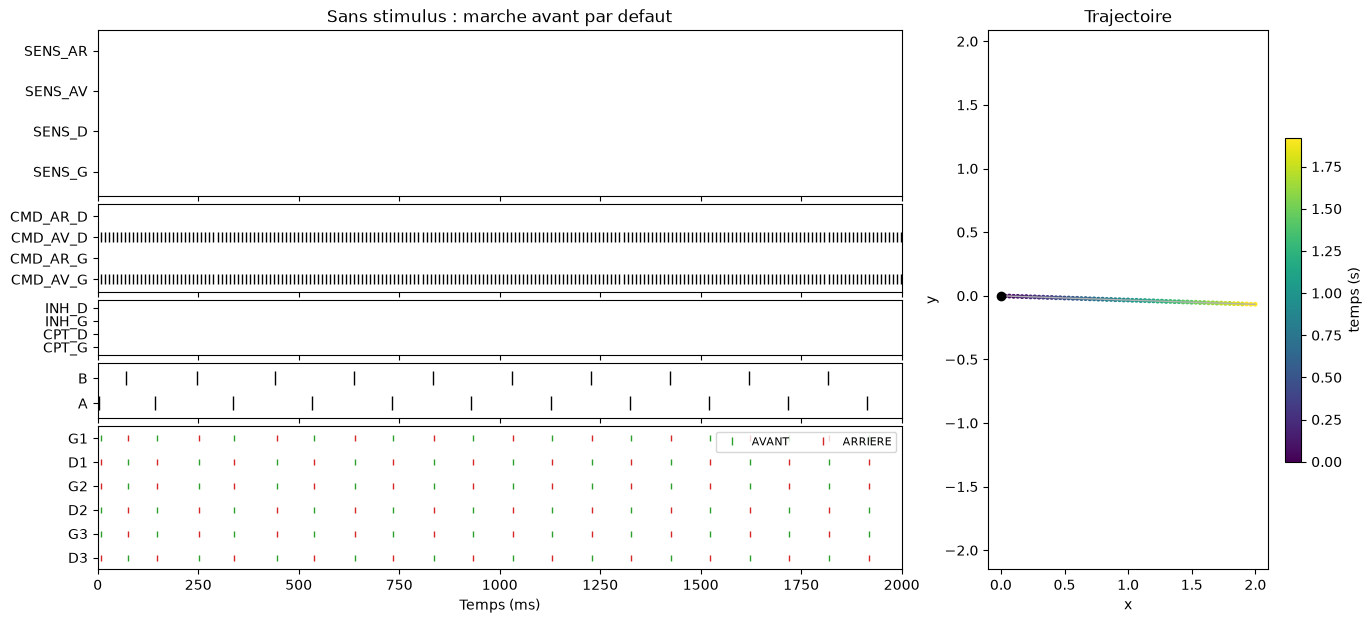

Decharges des commandes : {'CMD_AV_G': np.int64(200), 'CMD_AR_G': np.int64(0), 'CMD_AV_D': np.int64(200), 'CMD_AR_D': np.int64(0)}
Position finale : x = 2.00, y = -0.07, theta = 0.00 rad  (Partie I : x = 2.00)


In [6]:
R = simuler(duree=2*second)
afficher(R, 'Sans stimulus : marche avant par defaut')
traj = decoder(R)[0]
print('Decharges des commandes :', dict(zip(CMD_NOMS, np.bincount(R['CMD'][1], minlength=4))))
print(f"Position finale : x = {traj[-1, 1]:.2f}, y = {traj[-1, 2]:.2f}, theta = {traj[-1, 3]:.2f} rad  (Partie I : x = 2.00)")

## Étape 2 : neurones sensoriels, recrutement et codage de l'intensité
Chaque population a M = 10 neurones dont les seuils vont de 0.2 à 1.8. Le courant injecté est `K_SENS × intensité` pendant le contact (100 ms).
Un contact faible ne dépasse le seuil que de quelques neurones, qui déchargent lentement ; un contact fort en recrute plus, et plus vite → **codage par recrutement et par fréquence**.

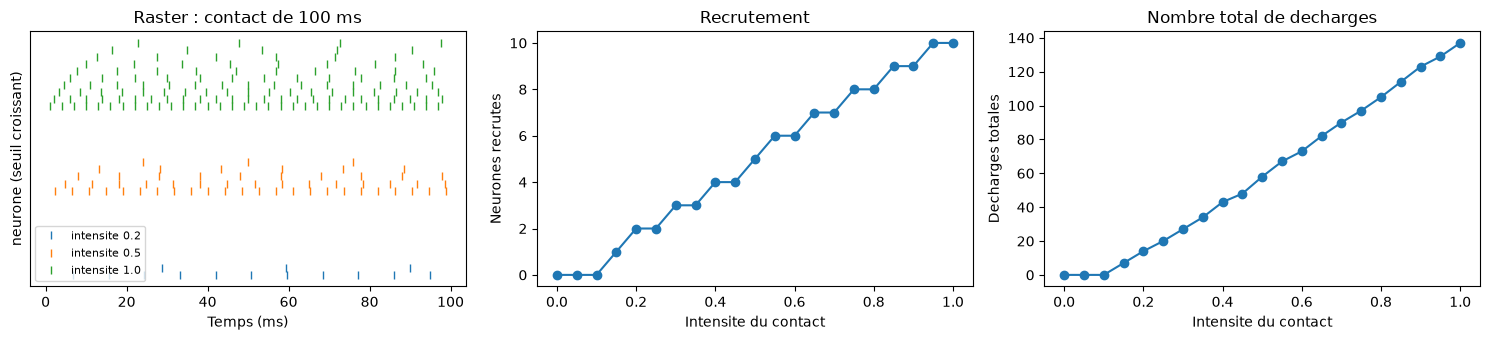

In [7]:
def recrutement(intensites, seuil_min=PARAM['SEUIL_MIN'], seuil_max=PARAM['SEUIL_MAX'], M=PARAM['M'],
                K=PARAM['K_SENS'], duree=100*ms):
    """Une population sensorielle par intensite (contact de 100 ms). Renvoie decharges et recrutes."""
    start_scope()
    nI = len(intensites)
    G = pop(nI * M, tau=10*ms, seuil=np.tile(np.linspace(seuil_min, seuil_max, M), nI))
    G.I = K * np.repeat(intensites, M)
    S = SpikeMonitor(G)
    run(duree)
    cnt = np.array(S.count).reshape(nI, M)
    return cnt.sum(1), (cnt > 0).sum(1), (S.t / ms, np.array(S.i))


I_vals = np.linspace(0, 1, 21)
tot, rec, _ = recrutement(I_vals)
_, _, (t, i) = recrutement([0.2, 0.5, 1.0])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for b, inten in enumerate([0.2, 0.5, 1.0]):
    m = i // PARAM['M'] == b
    ax[0].plot(t[m], i[m] % PARAM['M'] + b * (PARAM['M'] + 2), '|', ms=6, c=f'C{b}', label=f'intensite {inten}')
ax[0].set(xlabel='Temps (ms)', ylabel='neurone (seuil croissant)', yticks=[], title='Raster : contact de 100 ms')
ax[0].legend(fontsize=8)
ax[1].plot(I_vals, rec, 'o-'); ax[1].set(xlabel='Intensite du contact', ylabel='Neurones recrutes', title='Recrutement')
ax[2].plot(I_vals, tot, 'o-'); ax[2].set(xlabel='Intensite du contact', ylabel='Decharges totales', title='Nombre total de decharges')
plt.tight_layout(); plt.show()

**Persistance (synapses lentes).** Chaque décharge sensorielle ajoute `w` au courant lent `gs` du neurone de commande, qui décroît avec `tau_persist` = 800 ms (le plan suggérait 500 ms ; 800 ms donne des virages et des reculs plus visibles, voir l'étude 7.2). Le pic de `gs` est proportionnel au nombre de décharges, et la réaction dure tant que `gs` reste au-dessus du seuil : $t \approx \tau_{persist} \ln(g_{pic}/g_{seuil})$. Plus le contact est fort, plus la réaction **monte haut et dure longtemps**.

## Étape 3 : obstacle de face → reculer
SENS_AV excite CMD_AR_G et CMD_AR_D et inhibe CMD_AV_G et CMD_AV_D (synapses lentes). Les deux côtés passent en mode arrière, c'est-à-dire en marche arrière (Partie I). Quand le courant lent retombe, CMD_AV reprend le dessus grâce à son biais tonique (circuit *winner-take-all* CMD_AV ⟂ CMD_AR) et la marche avant reprend.

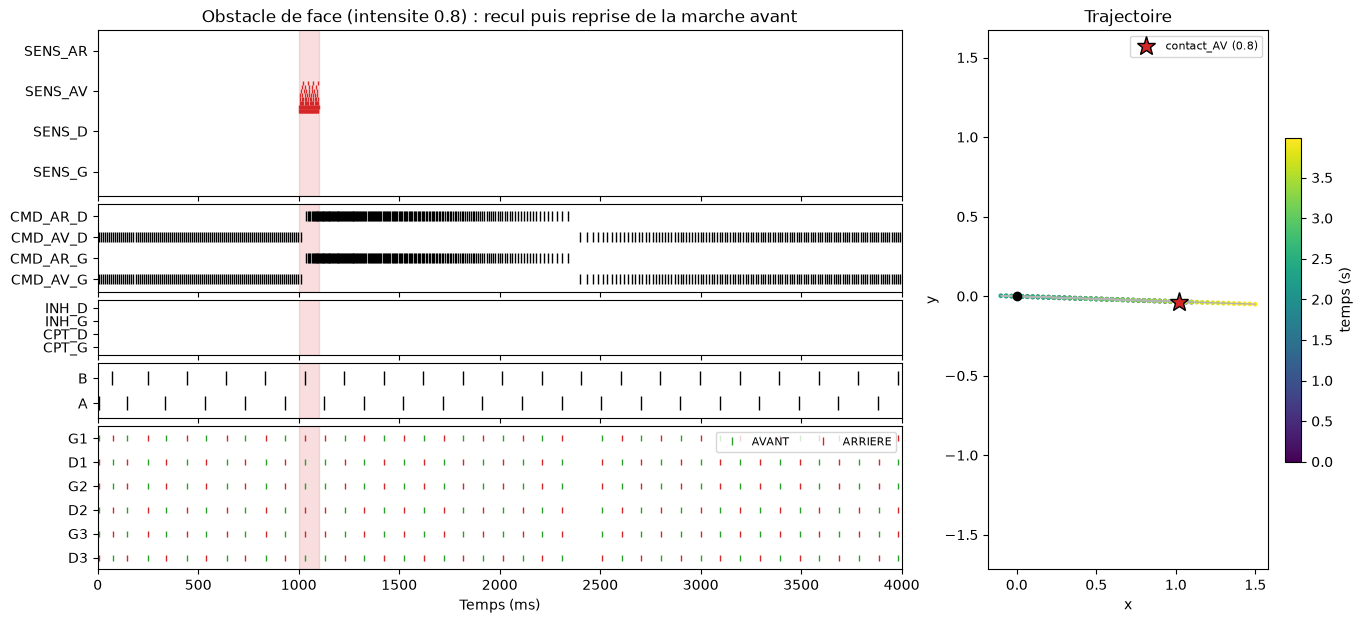

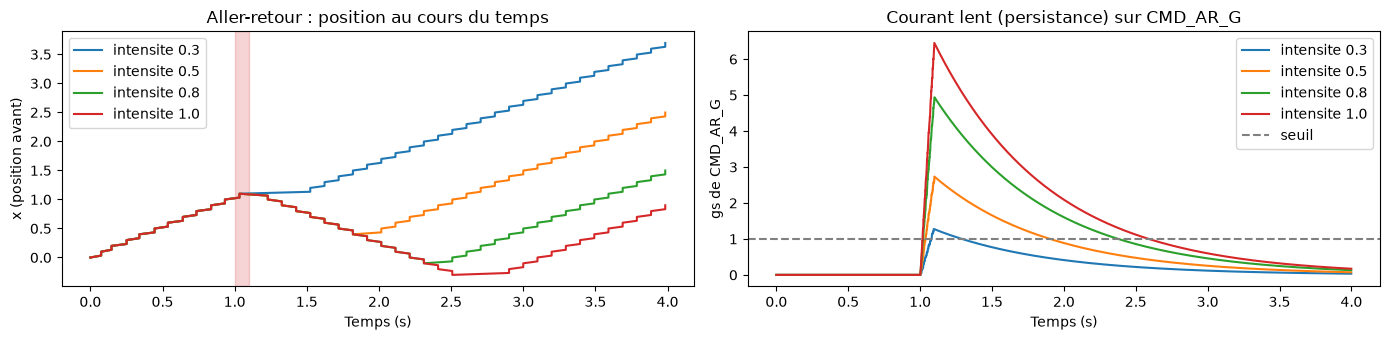

In [8]:
stim = [('AV', 1000*ms, 0.8, 100*ms)]
R = simuler(stim, duree=4*second)
afficher(R, 'Obstacle de face (intensite 0.8) : recul puis reprise de la marche avant', stim)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for inten in [0.3, 0.5, 0.8, 1.0]:
    R = simuler([('AV', 1000*ms, inten, 100*ms)], duree=4*second)
    traj = decoder(R)[0]
    ax[0].plot(traj[:, 0] / 1000, traj[:, 1], label=f'intensite {inten}')
    ax[1].plot(R['t_gs'] / 1000, R['gs_CMD'][1], label=f'intensite {inten}')
ax[0].axvspan(1, 1.1, color=COUL['AV'], alpha=0.2)
ax[0].set(xlabel='Temps (s)', ylabel='x (position avant)', title='Aller-retour : position au cours du temps'); ax[0].legend()
ax[1].axhline(1, ls='--', c='gray', label='seuil')
ax[1].set(xlabel='Temps (s)', ylabel='gs de CMD_AR_G', title='Courant lent (persistance) sur CMD_AR_G'); ax[1].legend()
plt.tight_layout(); plt.show()

À l'intensité 0.3, CMD_AV est inhibé mais `gs` de CMD_AR dépasse à peine le seuil : l'hexapode **s'arrête** brièvement sans vraiment reculer. Au-dessus, le recul dure d'autant plus longtemps que l'impact est fort.

**Durée du recul en fonction de l'intensité.** On mesure la durée d'activité de CMD_AR_G (= durée du mode arrière). Seulement capteurs + commandes (`pattes=False`), car la durée du recul est fixée au niveau des commandes.

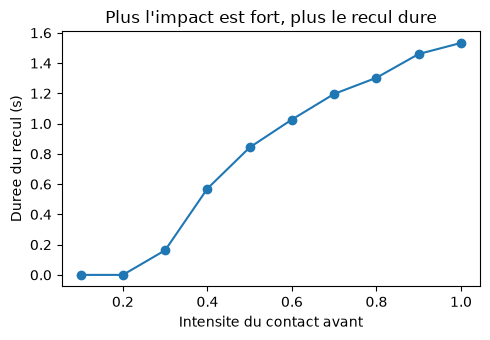

In [9]:
I_vals = np.round(np.linspace(0.1, 1.0, 10), 2)
dur_recul = []
for inten in I_vals:
    R = simuler([('AV', 200*ms, inten, 100*ms)], duree=3*second, pattes=False)
    dur_recul.append(duree_active(R, 'CMD', 1, 200))
plt.figure(figsize=(5, 3.5))
plt.plot(I_vals, np.array(dur_recul) / 1000, 'o-')
plt.xlabel('Intensite du contact avant'); plt.ylabel('Duree du recul (s)'); plt.title('Plus l\'impact est fort, plus le recul dure')
plt.tight_layout(); plt.show()

## Étape 4 : heurté par derrière → accélérer
SENS_AR excite A et B du CPG par une synapse lente : le drive effectif `I_drive + gs` augmente, le CPG accélère (plus de pas par seconde), puis revient à la cadence de croisière quand `gs` décroît.

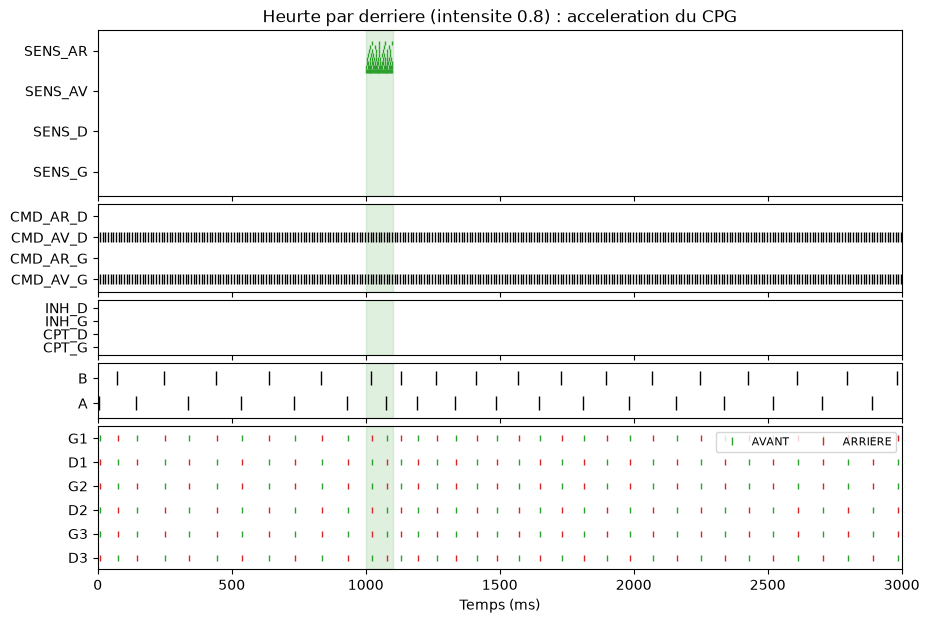

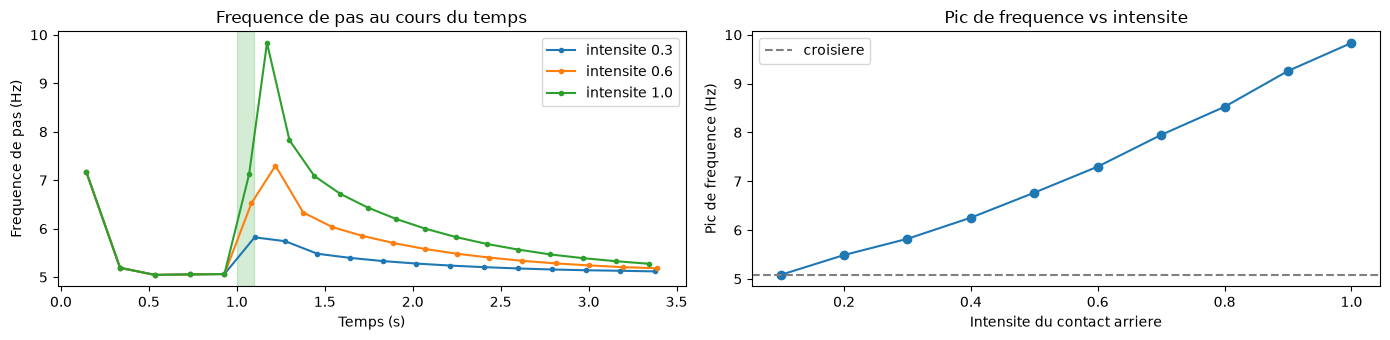

In [10]:
stim = [('AR', 1000*ms, 0.8, 100*ms)]
R = simuler(stim, duree=3*second)
afficher(R, 'Heurte par derriere (intensite 0.8) : acceleration du CPG', stim, traj=False)

I_vals = np.round(np.linspace(0.1, 1.0, 10), 2)
pic = []
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for inten in I_vals:
    R = simuler([('AR', 1000*ms, inten, 100*ms)], duree=3.5*second, pattes=False)
    t, f = freq_pas(R)
    pic.append(f[t > 1000].max())
    if inten in (0.3, 0.6, 1.0): ax[0].plot(t / 1000, f, 'o-', ms=3, label=f'intensite {inten}')
ax[0].axvspan(1, 1.1, color=COUL['AR'], alpha=0.2)
ax[0].set(xlabel='Temps (s)', ylabel='Frequence de pas (Hz)', title='Frequence de pas au cours du temps'); ax[0].legend()
ax[1].plot(I_vals, pic, 'o-'); ax[1].axhline(f[(t > 300) & (t < 1000)].mean(), ls='--', c='gray', label='croisiere')
ax[1].set(xlabel='Intensite du contact arriere', ylabel='Pic de frequence (Hz)', title='Pic de frequence vs intensite'); ax[1].legend()
plt.tight_layout(); plt.show()

## Étape 5 : obstacle sur un flanc → tourner (réponse graduée)
SENS_D excite COMPTEUR_G. Le compteur reçoit déjà les salves de A ; avec le courant sensoriel en plus, il atteint son seuil plus vite, donc il décharge une salve sur n avec n plus petit. Chaque décharge du compteur active INHIB_G qui bloque les interneurones gauches pendant ~un cycle : les pattes gauches sautent des poussées et l'hexapode tourne à gauche.
- **contact faible** : n grand → courbe douce ;
- **contact moyen** : n = 1 (le compteur décharge à chaque cycle) → virage serré ;
- **contact fort** : la voie à poids faible SENS_D → CMD_AR_G franchit le seuil (elle doit vaincre l'inhibition WTA de CMD_AV_G). Le côté gauche passe en mode arrière → **rotation sur place**. CMD_AR_G inhibe aussi COMPTEUR_G (ajout de notre part) : sinon le compteur bloquerait les pattes gauches et empêcherait le pivot.

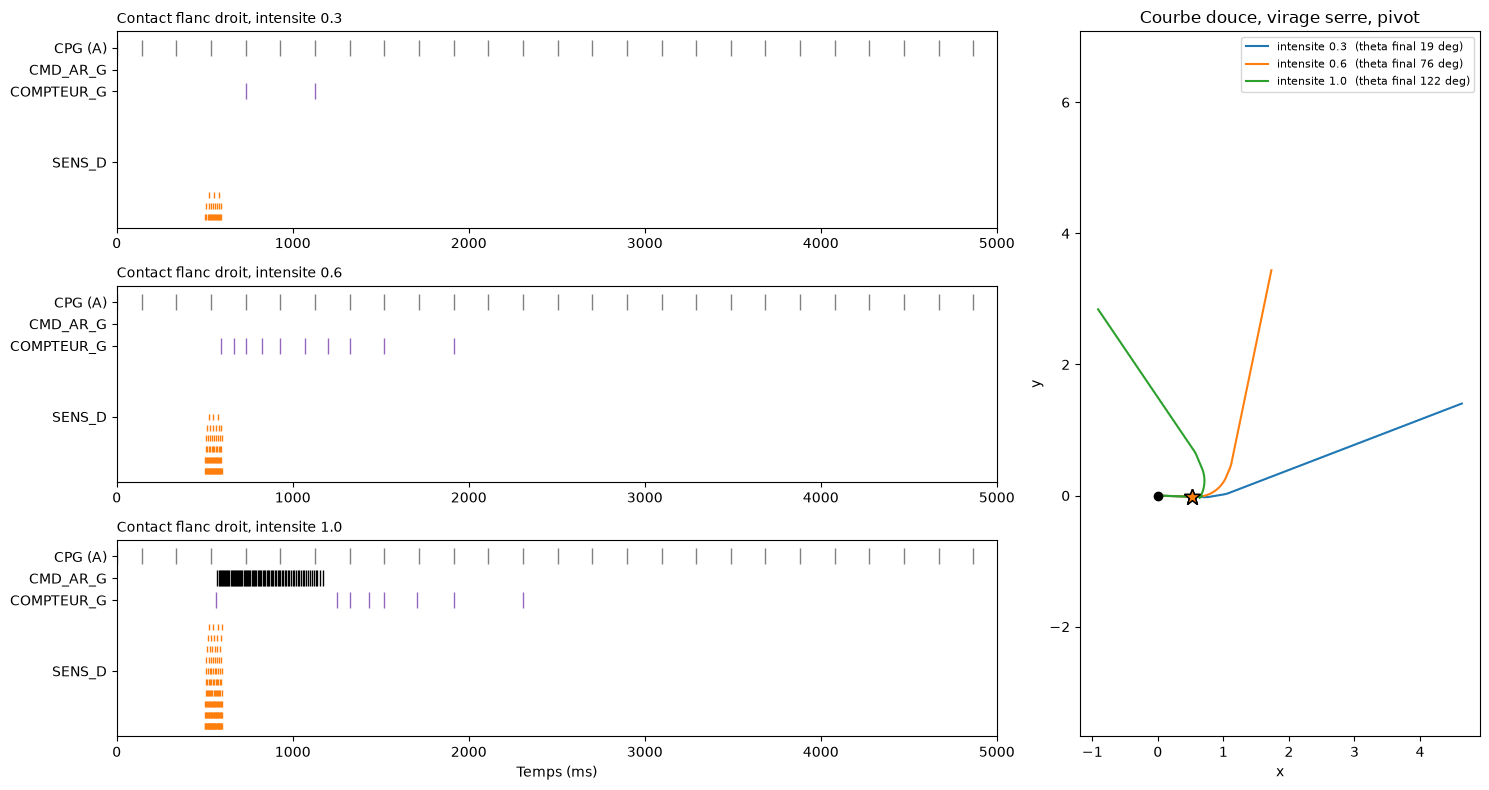

In [11]:
res_virage = {}
for inten in [0.3, 0.6, 1.0]:
    res_virage[inten] = simuler([('D', 500*ms, inten, 100*ms)], duree=5*second)

fig, ax = plt.subplots(3, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [2.2, 1]})
gs_ = ax[0, 1].get_gridspec()
for a in ax[:, 1]: a.remove()
at = fig.add_subplot(gs_[:, 1])
for r, (inten, R) in enumerate(res_virage.items()):
    M = R['M']
    t, i = R['S_D']; ax[r, 0].plot(t, i, '|', c=COUL['D'], ms=4)
    t = activite(R, 'CPT', 0); ax[r, 0].plot(t, np.full(len(t), M + 1.5), '|', c='C4', ms=12)
    t = activite(R, 'CMD', 1); ax[r, 0].plot(t, np.full(len(t), M + 3.5), '|', c='k', ms=12)
    t = activite(R, 'CPG', 0); ax[r, 0].plot(t, np.full(len(t), M + 5.5), '|', c='0.5', ms=12)
    ax[r, 0].set(yticks=[M / 2, M + 1.5, M + 3.5, M + 5.5], yticklabels=['SENS_D', 'COMPTEUR_G', 'CMD_AR_G', 'CPG (A)'],
                 xlim=(0, 5000), ylim=(-1, M + 7))
    ax[r, 0].set_title(f'Contact flanc droit, intensite {inten}', fontsize=10, loc='left')
    traj = decoder(R)[0]
    at.plot(traj[:, 1], traj[:, 2], label=f'intensite {inten}  (theta final {np.degrees(traj[-1, 3]):.0f} deg)')
    at.plot(*pos_a(traj, 500), '*', c=COUL['D'], ms=12, mec='k')
ax[2, 0].set_xlabel('Temps (ms)')
at.plot(0, 0, 'ko'); at.set_aspect('equal', adjustable='datalim')
at.set(xlabel='x', ylabel='y', title='Courbe douce, virage serre, pivot'); at.legend(fontsize=8)
plt.tight_layout(); plt.show()

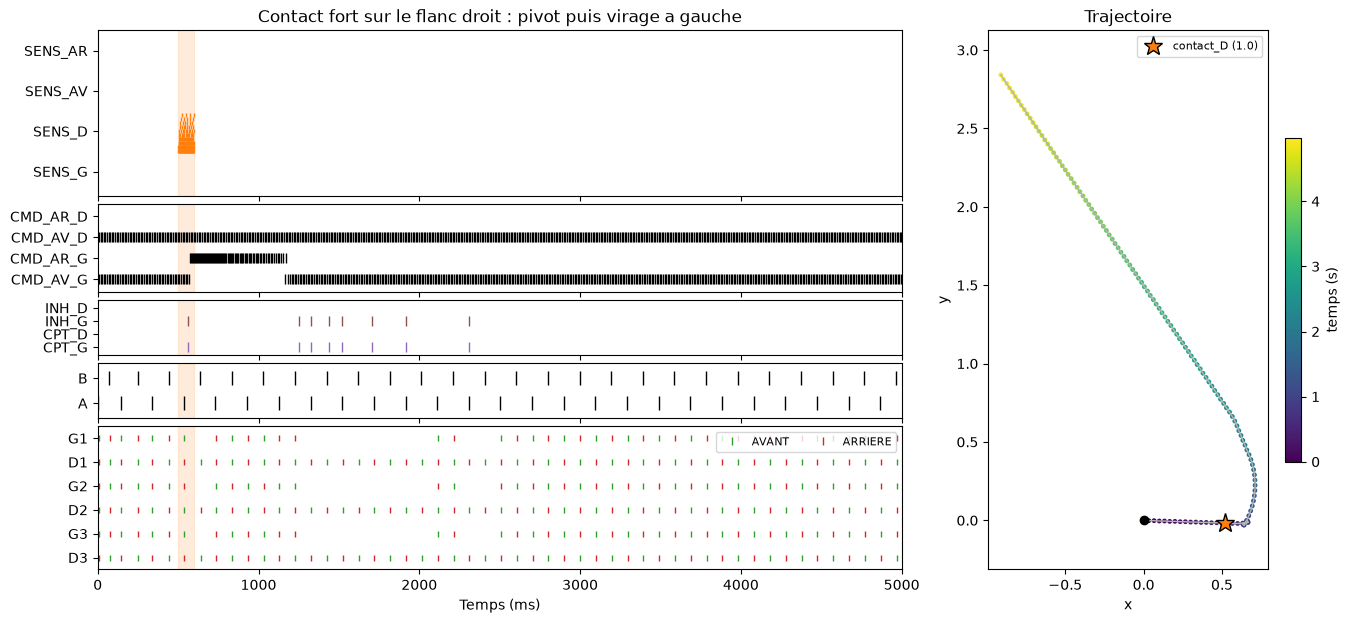

In [12]:
stim = [('D', 500*ms, 1.0, 100*ms)]
afficher(res_virage[1.0], 'Contact fort sur le flanc droit : pivot puis virage a gauche', stim)

**Flanc gauche → tourner à droite** : même mécanisme en symétrique (SENS_G → COMPTEUR_D et CMD_AR_D).

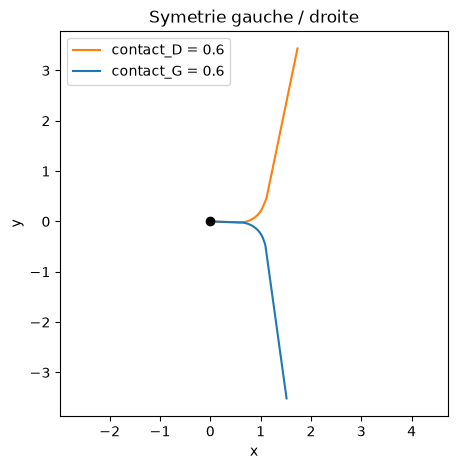

In [13]:
plt.figure(figsize=(5, 5))
for cap, inten in [('D', 0.6), ('G', 0.6)]:
    traj = decoder(res_virage[inten] if cap == 'D' else simuler([(cap, 500*ms, inten, 100*ms)], duree=5*second))[0]
    plt.plot(traj[:, 1], traj[:, 2], c=COUL[cap], label=f'contact_{cap} = {inten}')
plt.plot(0, 0, 'ko'); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.legend()
plt.title('Symetrie gauche / droite'); plt.show()

## Étape 6 : sélection d'action (stimuli simultanés)
Hiérarchie **AVANT > FLANCS > ARRIÈRE**, implémentée par de l'inhibition rapide entre les voies sensorielles :
SENS_AV inhibe SENS_G, SENS_D, SENS_AR ; SENS_G et SENS_D inhibent SENS_AR ; SENS_G ⟂ SENS_D (le plus fort l'emporte).

Trois conflits :
1. obstacle devant **et** à droite → on recule (pas de virage) ;
2. contact à gauche (0.4) **et** à droite (0.8) → le côté le plus fort gagne : virage à gauche ;
3. contact à droite **et** poussée arrière → on tourne, sans accélérer.

scenario           SENS_G   SENS_D  SENS_AV  SENS_AR   pic freq (Hz)


AV 0.6 + D 0.6          0        1       73        0   7.2


G 0.4 + D 0.8           0      105        0        0   7.2


D 0.6 + AR 0.8          0       73        0        1   7.2


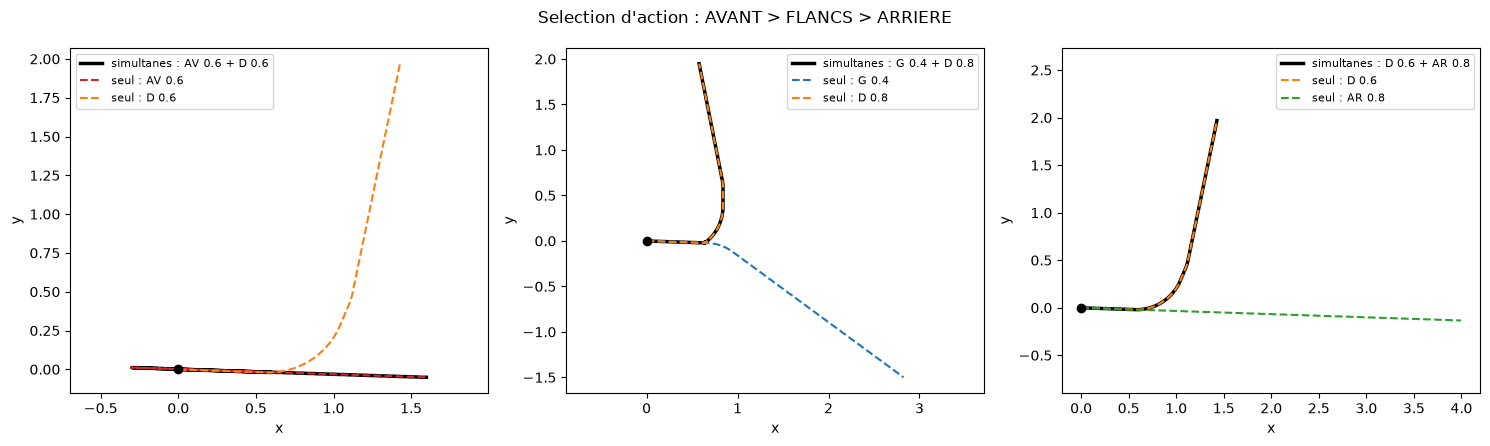

In [14]:
conflits = {
    'AV 0.6 + D 0.6':  [('AV', 500*ms, 0.6, 100*ms), ('D', 500*ms, 0.6, 100*ms)],
    'G 0.4 + D 0.8':   [('G', 500*ms, 0.4, 100*ms), ('D', 500*ms, 0.8, 100*ms)],
    'D 0.6 + AR 0.8':  [('D', 500*ms, 0.6, 100*ms), ('AR', 500*ms, 0.8, 100*ms)],
}
seuls = {'AV 0.6': [('AV', 500*ms, 0.6, 100*ms)], 'D 0.6': [('D', 500*ms, 0.6, 100*ms)],
         'G 0.4': [('G', 500*ms, 0.4, 100*ms)], 'D 0.8': [('D', 500*ms, 0.8, 100*ms)], 'AR 0.8': [('AR', 500*ms, 0.8, 100*ms)]}
print(f"{'scenario':<16}" + ''.join(f'{"SENS_" + c:>9}' for c in CAPTEURS) + '   pic freq (Hz)')
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (nom, stim) in zip(ax, conflits.items()):
    Rc = simuler(stim, duree=3.5*second)
    print(f'{nom:<16}' + ''.join(f"{len(Rc['S_' + c][0]):>9}" for c in CAPTEURS) + f'   {freq_pas(Rc)[1].max():.1f}')
    traj = decoder(Rc)[0]
    a.plot(traj[:, 1], traj[:, 2], 'k', lw=2.5, label=f'simultanes : {nom}')
    for part in nom.split(' + '):
        traj = decoder(simuler(seuls[part], duree=3.5*second))[0]
        a.plot(traj[:, 1], traj[:, 2], '--', c=COUL[part.split()[0]], label=f'seul : {part}')
    a.plot(0, 0, 'ko'); a.set_aspect('equal', adjustable='datalim'); a.legend(fontsize=8); a.set(xlabel='x', ylabel='y')
plt.suptitle("Selection d'action : AVANT > FLANCS > ARRIERE"); plt.tight_layout(); plt.show()

## Étape 7 : adapter les comportements en modifiant les paramètres
| Paramètre modifié | Comportement adapté |
|---|---|
| Poids sensoriel → commande (`W_AV_AR`) | Sensibilité : intensité minimale pour réagir |
| `tau_persist` | Durée de la réaction |
| Délai sensoriel → commande (`DELAI_SENS`) | Temps de réaction (latence) |
| Poids faible SENS_D → CMD_AR_G (`W_LAT_AR`) | Seuil de passage virage → rotation |
| Seuils des neurones sensoriels | Plage d'intensités discriminées |
| `tau_a` du CPG, `I_drive_base` | Cadence de base (Partie I) |

### 7.1 Sensibilité (poids SENS_AV → CMD)
Réaction = CMD_AR_G décharge (l'hexapode recule). `W_AV_AV` est changé dans la même proportion.

W_AV_AR = 0.03 : intensite minimale pour reculer = 0.4


W_AV_AR = 0.05 : intensite minimale pour reculer = 0.3


W_AV_AR = 0.08 : intensite minimale pour reculer = 0.25


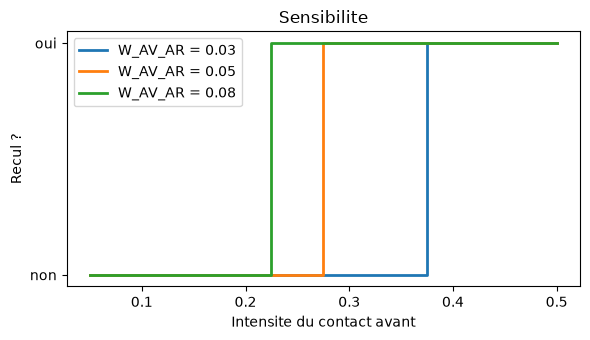

In [15]:
I_vals = np.round(np.linspace(0.05, 0.5, 10), 3)
plt.figure(figsize=(6, 3.5))
for w in [0.03, 0.05, 0.08]:
    rep = []
    for inten in I_vals:
        R = simuler([('AV', 200*ms, inten, 100*ms)], duree=1.5*second, pattes=False, W_AV_AR=w, W_AV_AV=0.8 * w)
        rep.append(len(activite(R, 'CMD', 1)) > 0)
    plt.step(I_vals, rep, where='mid', lw=2, label=f'W_AV_AR = {w}')
    print(f'W_AV_AR = {w} : intensite minimale pour reculer = {I_vals[np.argmax(rep)] if any(rep) else "> 0.5"}')
plt.yticks([0, 1], ['non', 'oui']); plt.xlabel('Intensite du contact avant'); plt.ylabel('Recul ?')
plt.title('Sensibilite'); plt.legend(); plt.tight_layout(); plt.show()

### 7.2 Durée de la réaction (`tau_persist`)

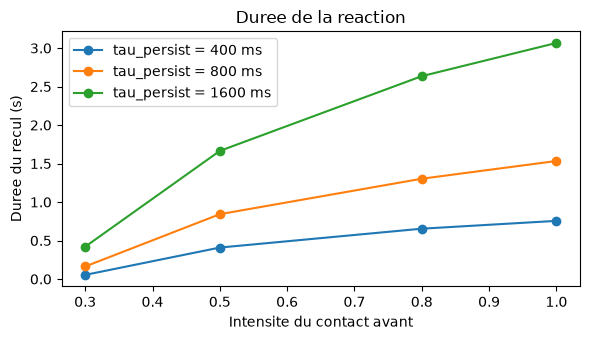

In [16]:
I_vals = [0.3, 0.5, 0.8, 1.0]
plt.figure(figsize=(6, 3.5))
for tp in [400, 800, 1600]:
    dur = []
    for inten in I_vals:
        R = simuler([('AV', 200*ms, inten, 100*ms)], duree=5*second, pattes=False, TAU_PERSIST=tp*ms)
        dur.append(duree_active(R, 'CMD', 1, 200) / 1000)
    plt.plot(I_vals, dur, 'o-', label=f'tau_persist = {tp} ms')
plt.xlabel('Intensite du contact avant'); plt.ylabel('Duree du recul (s)'); plt.title('Duree de la reaction')
plt.legend(); plt.tight_layout(); plt.show()

### 7.3 Temps de réaction (délai capteur → commande)
On mesure la distance parcourue entre le contact et le début du recul.

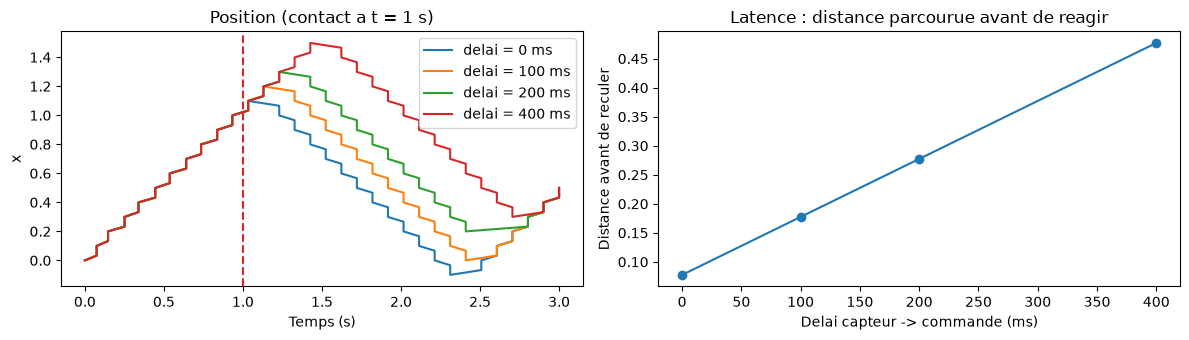

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
delais, dist = [0, 100, 200, 400], []
for dl in delais:
    R = simuler([('AV', 1000*ms, 0.8, 100*ms)], duree=3*second, DELAI_SENS=dl*ms)
    traj = decoder(R)[0]
    x0 = pos_a(traj, 1000)[0]
    dist.append(traj[:, 1].max() - x0)
    ax[0].plot(traj[:, 0] / 1000, traj[:, 1], label=f'delai = {dl} ms')
ax[0].axvline(1, c=COUL['AV'], ls='--'); ax[0].set(xlabel='Temps (s)', ylabel='x', title='Position (contact a t = 1 s)'); ax[0].legend()
ax[1].plot(delais, dist, 'o-'); ax[1].set(xlabel='Delai capteur -> commande (ms)', ylabel='Distance avant de reculer',
                                          title='Latence : distance parcourue avant de reagir')
plt.tight_layout(); plt.show()

### 7.4 Seuil de passage virage → rotation (poids faible SENS_D → CMD_AR_G)
Pivot = CMD_AR_G décharge.

W_LAT_AR = 0.02 : bascule virage -> pivot a l'intensite 0.8


W_LAT_AR = 0.025 : bascule virage -> pivot a l'intensite 0.7


W_LAT_AR = 0.035 : bascule virage -> pivot a l'intensite 0.6


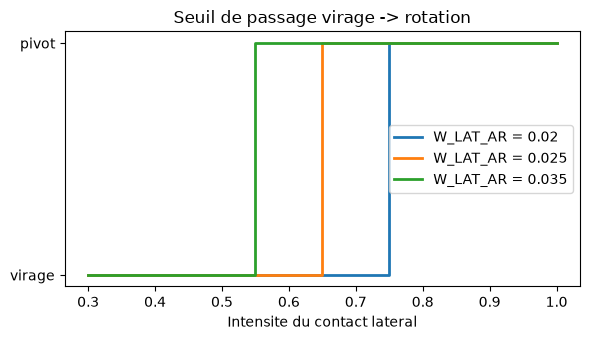

In [18]:
I_vals = np.round(np.linspace(0.3, 1.0, 8), 2)
plt.figure(figsize=(6, 3.5))
for w in [0.02, 0.025, 0.035]:
    piv = []
    for inten in I_vals:
        R = simuler([('D', 200*ms, inten, 100*ms)], duree=1.5*second, pattes=False, W_LAT_AR=w)
        piv.append(len(activite(R, 'CMD', 1)) > 0)
    plt.step(I_vals, piv, where='mid', lw=2, label=f'W_LAT_AR = {w}')
    print(f'W_LAT_AR = {w} : bascule virage -> pivot a l\'intensite {I_vals[np.argmax(piv)] if any(piv) else "> 1"}')
plt.yticks([0, 1], ['virage', 'pivot']); plt.xlabel('Intensite du contact lateral')
plt.title('Seuil de passage virage -> rotation'); plt.legend(); plt.tight_layout(); plt.show()

### 7.5 Seuils des neurones sensoriels → plage d'intensités discriminées
Des seuils resserrés donnent une réponse en tout-ou-rien (plage étroite) ; des seuils étalés discriminent une large plage d'intensités.

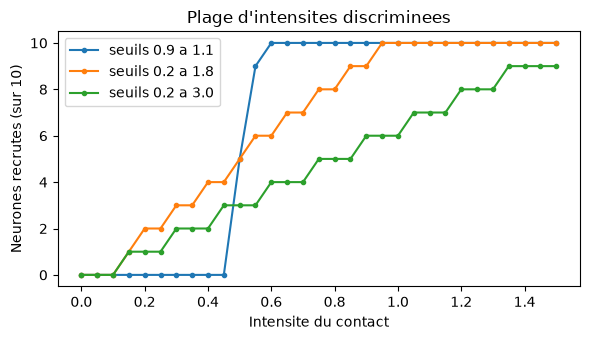

In [19]:
I_vals = np.linspace(0, 1.5, 31)
plt.figure(figsize=(6, 3.5))
for smin, smax in [(0.9, 1.1), (0.2, 1.8), (0.2, 3.0)]:
    plt.plot(I_vals, recrutement(I_vals, smin, smax)[1], 'o-', ms=3, label=f'seuils {smin} a {smax}')
plt.xlabel('Intensite du contact'); plt.ylabel('Neurones recrutes (sur 10)'); plt.title('Plage d\'intensites discriminees')
plt.legend(); plt.tight_layout(); plt.show()

## Étape 8 : généralisation à N paires de pattes
Les capteurs et les commandes sont **par côté**, pas par patte : on change seulement `N_PAIRES`. Même scénario (contact à droite 0.6 à t = 0.5 s, puis obstacle devant 0.8 à t = 3 s) pour N = 3, 20 et 200. Chaque patte porte `d / N_PAIRES`, donc les trajectoires doivent être comparables.

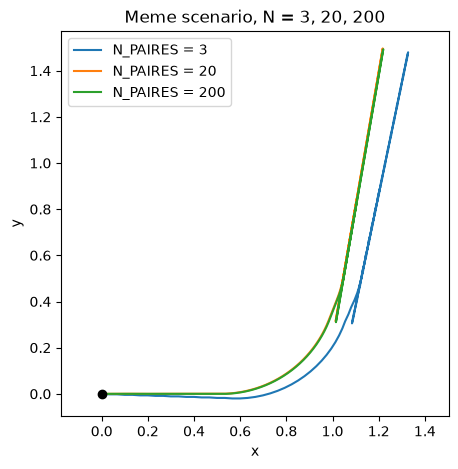

In [20]:
scenario = [('D', 500*ms, 0.6, 100*ms), ('AV', 3000*ms, 0.8, 100*ms)]
res_N = {N: simuler(scenario, N_PAIRES=N, delta=dl, duree=5*second) for N, dl in [(3, 0*ms), (20, 5*ms), (200, 0.5*ms)]}
plt.figure(figsize=(5, 5))
for N, R in res_N.items():
    traj = decoder(R)[0]
    plt.plot(traj[:, 1], traj[:, 2], label=f'N_PAIRES = {N}')
plt.plot(0, 0, 'ko'); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.legend()
plt.title('Meme scenario, N = 3, 20, 200'); plt.show()

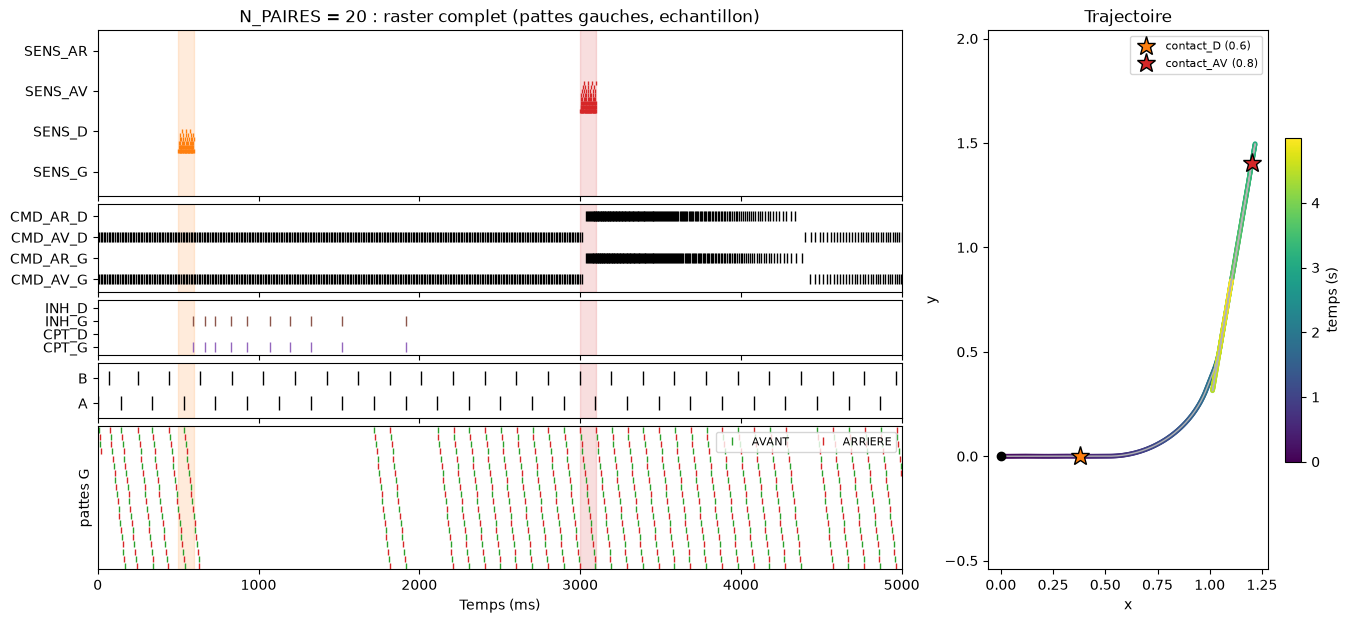

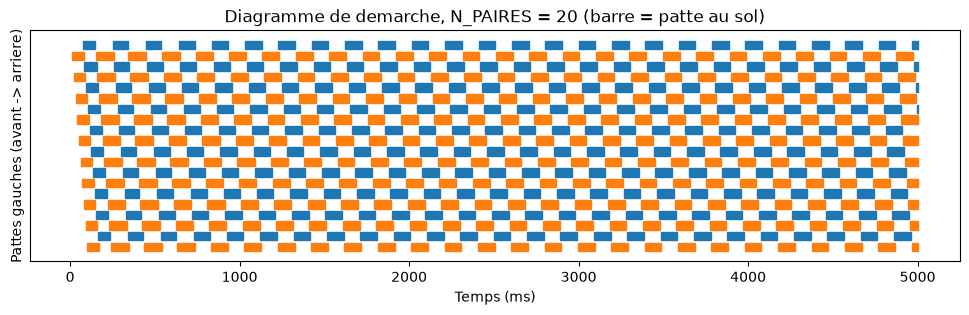

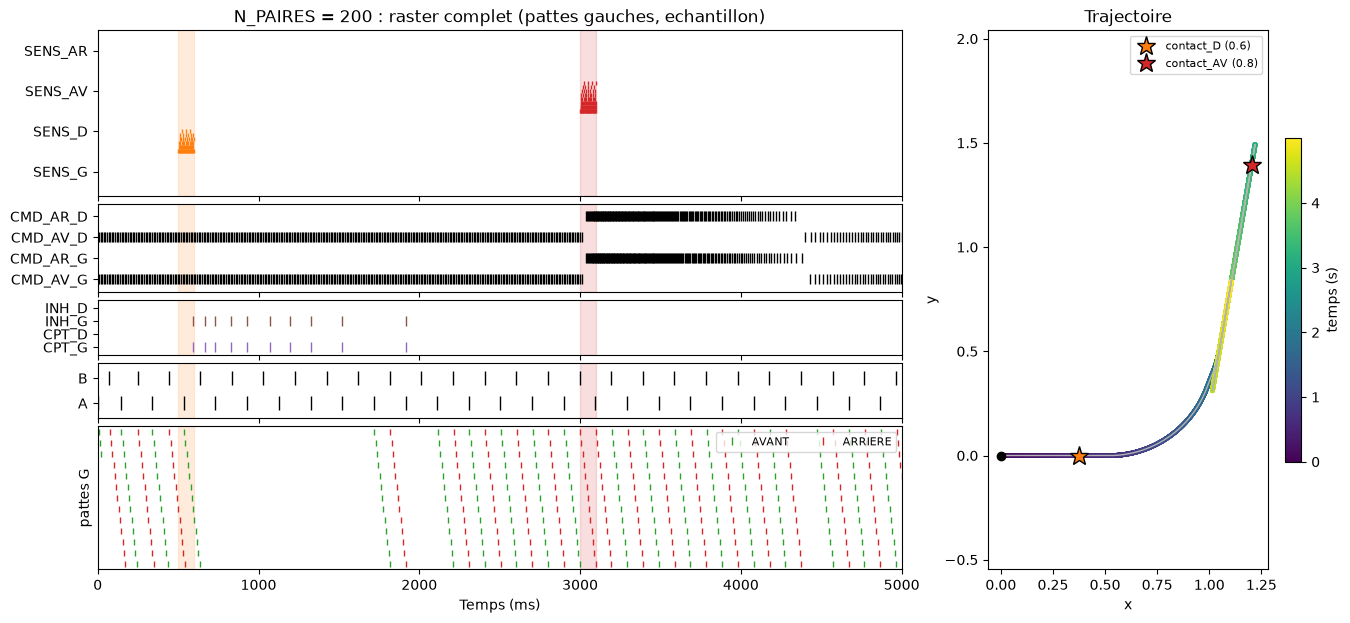

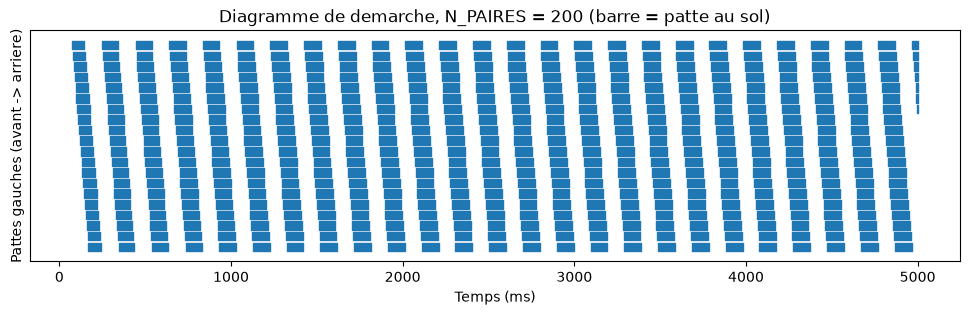

In [21]:
for N in [20, 200]:
    afficher(res_N[N], f'N_PAIRES = {N} : raster complet (pattes gauches, echantillon)', scenario)
    contact = decoder(res_N[N])[1]
    n = res_N[N]['n']
    pattes = range(0, n, 2 * max(1, n // 40))
    plt.figure(figsize=(12, 3))
    for r, p in enumerate(pattes):
        plt.broken_barh([(a, b - a) for a, b in contact[p]], (r - 0.4, 0.8), color=f'C{(p // 2 + p % 2) % 2}')
    plt.gca().invert_yaxis(); plt.yticks([])
    plt.xlabel('Temps (ms)'); plt.ylabel('Pattes gauches (avant -> arriere)')
    plt.title(f'Diagramme de demarche, N_PAIRES = {N} (barre = patte au sol)'); plt.show()

## Étape 9 (bonus) : habituation
Dépression synaptique à court terme sur SENS_AR → CPG : chaque décharge consomme une fraction `U_STD` de la ressource `x` de la synapse, qui se reconstitue avec `TAU_REC` = 4 s. Si l'hexapode se fait pousser plusieurs fois de suite, il accélère de moins en moins : le système s'adapte de lui-même.

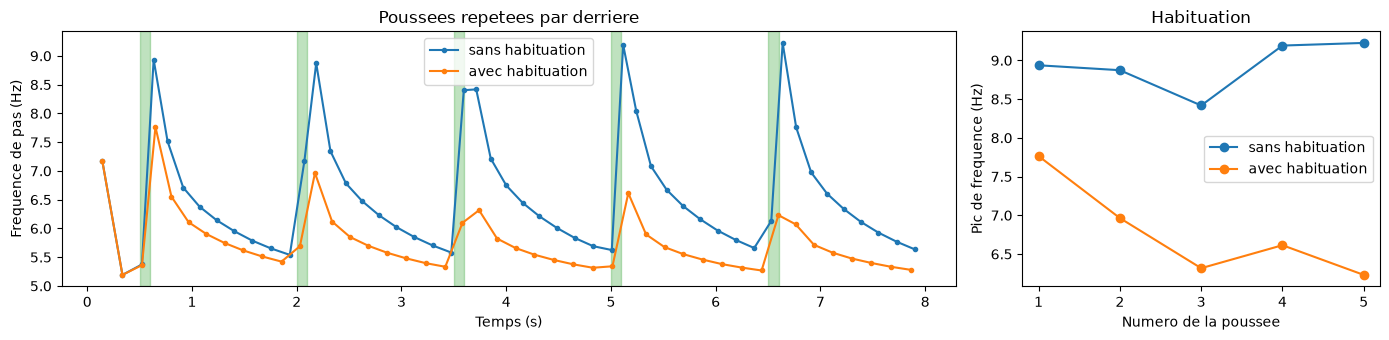

In [22]:
pousses = [('AR', t0 * ms, 0.8, 100*ms) for t0 in [500, 2000, 3500, 5000, 6500]]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'width_ratios': [2.5, 1]})
for hab, lab in [(False, 'sans habituation'), (True, 'avec habituation')]:
    R = simuler(pousses, duree=8*second, pattes=False, HABITUATION=hab)
    t, f = freq_pas(R)
    ax[0].plot(t / 1000, f, 'o-', ms=3, label=lab)
    pics = [f[(t > p[1] / ms) & (t < p[1] / ms + 1500)].max() for p in pousses]
    ax[1].plot(range(1, len(pousses) + 1), pics, 'o-', label=lab)
for p in pousses: ax[0].axvspan(p[1] / second, p[1] / second + 0.1, color=COUL['AR'], alpha=0.3)
ax[0].set(xlabel='Temps (s)', ylabel='Frequence de pas (Hz)', title='Poussees repetees par derriere'); ax[0].legend()
ax[1].set(xlabel='Numero de la poussee', ylabel='Pic de frequence (Hz)', title='Habituation'); ax[1].legend()
plt.tight_layout(); plt.show()

## Étape 9 (bonus) : boucle fermée dans une arène
Un `network_operation` de Brian2 tourne toutes les 10 ms : il lit les nouvelles décharges des motoneurones, met à jour la position avec le décodeur (en ligne), et teste si le corps (cercle de rayon 0.5) touche un mur.
- L'angle φ du mur par rapport au cap choisit le capteur : |φ| < 45° → avant ; 45° à 135° → flanc gauche ; −135° à −45° → flanc droit ; sinon arrière.
- L'intensité est la composante normale de l'impact, |cos φ| (au moins 0.3) : un mur de face donne un contact fort, un mur frôlé un contact faible.
- Le courant `K_SENS × intensité` est injecté pendant 100 ms, puis le capteur est réfractaire 400 ms.
- Option de la section 3 activée (`W_AV_CPT`) : après un recul, le compteur gauche fait tourner l'hexapode, pour ne pas retomber sur le même mur.

Personne ne fixe les stimuli : l'hexapode **explore son environnement tout seul**.

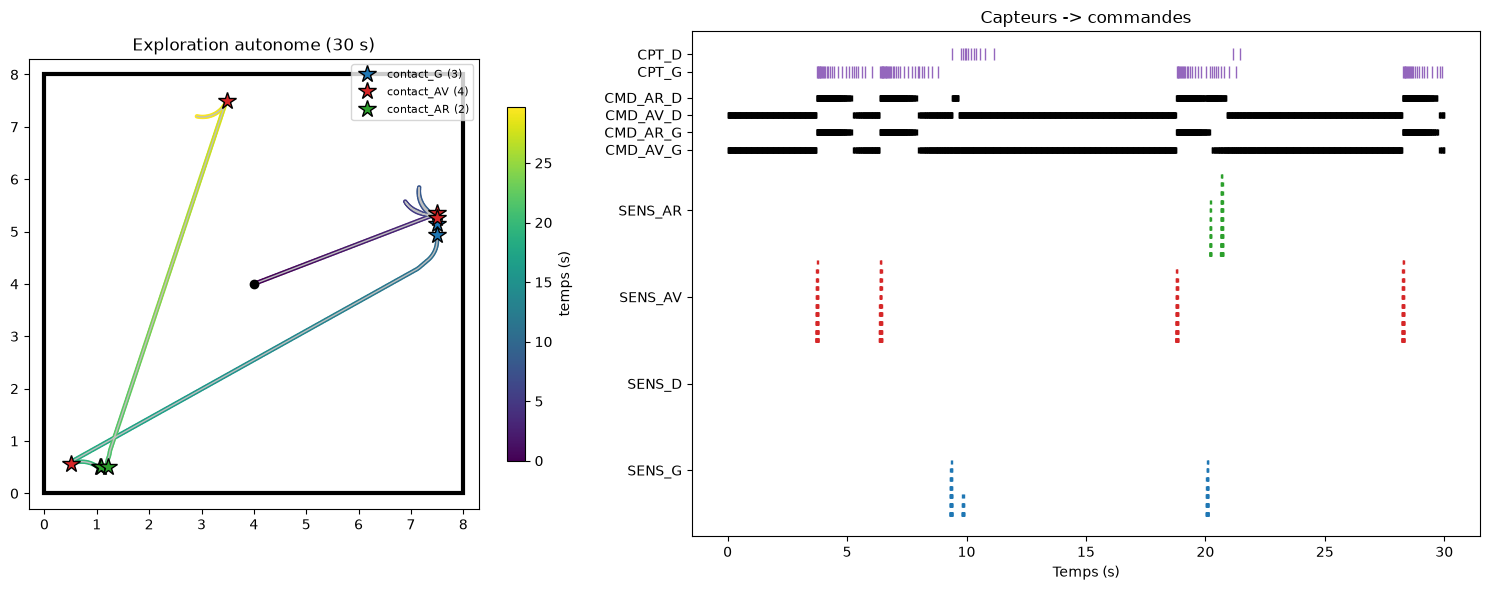

9 contacts : AV@3.7s(0.92), AV@6.3s(0.96), G@9.3s(0.65), G@9.8s(0.30), AV@18.8s(0.89), G@20.0s(0.66), AR@20.1s(0.71), AR@20.6s(0.98), AV@28.2s(0.94)


In [23]:
def arene(duree=20*second, taille=8.0, rayon=0.5, depart=(4.0, 4.0, 0.4), N_PAIRES=3, **p):
    P_ = PARAM | p
    journal = {'contacts': []}

    def extra(G):
        D = Decodeur(G['n'], x=depart[0], y=depart[1], th=depart[2],
                     limites=(rayon, taille - rayon, rayon, taille - rayon))
        lus = dict.fromkeys(['LEVER', 'POSER', 'AVANT', 'ARRIERE'], 0)
        fin, pret = dict.fromkeys(CAPTEURS, -1.0), dict.fromkeys(CAPTEURS, 0.0)
        murs = [(0.0, lambda x, y: x >= taille - rayon - 1e-9), (np.pi, lambda x, y: x <= rayon + 1e-9),
                (np.pi / 2, lambda x, y: y >= taille - rayon - 1e-9), (-np.pi / 2, lambda x, y: y <= rayon + 1e-9)]
        journal['D'] = D

        @network_operation(dt=10*ms)
        def monde(t):
            T = float(t / ms)
            ev = []
            for c in lus:                                      # nouvelles decharges motrices
                m, k0 = G[c], lus[c]
                k1 = m.num_spikes
                if k1 > k0:
                    ev += list(zip(np.asarray(m.t[k0:k1] / ms), np.asarray(m.i[k0:k1]), [c] * (k1 - k0)))
                    lus[c] = k1
            for e in sorted(ev): D.evenement(*e)
            for psi, touche in murs:                           # contact avec un mur
                if not touche(D.x, D.y): continue
                phi = (psi - D.th + np.pi) % (2 * np.pi) - np.pi
                cap = 'AV' if abs(phi) < np.pi / 4 else 'AR' if abs(phi) > 3 * np.pi / 4 else 'G' if phi > 0 else 'D'
                if T >= pret[cap]:
                    inten = max(0.3, abs(np.cos(phi)))
                    fin[cap], pret[cap] = T + 100, T + 500
                    G['SENS'][cap].I = P_['K_SENS'] * inten
                    journal['contacts'].append((T, cap, inten, D.x, D.y))
            for cap in CAPTEURS:                               # fin de l'impulsion de 100 ms
                if T >= fin[cap]: G['SENS'][cap].I = 0
        return [monde]

    R = simuler(None, N_PAIRES=N_PAIRES, duree=duree, extra=extra, **p)
    return R, np.array(journal['D'].traj), journal['contacts']


R, traj, contacts = arene(duree=30*second, W_AV_CPT=0.12)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.4]})
ax[0].add_patch(plt.Rectangle((0, 0), 8, 8, fill=False, lw=3))
ax[0].plot(traj[:, 1], traj[:, 2], c='0.75', lw=1)
sc = ax[0].scatter(traj[:, 1], traj[:, 2], c=traj[:, 0] / 1000, s=5, cmap='viridis')
for cap in CAPTEURS:
    pts = [(x, y) for (_, c, _, x, y) in contacts if c == cap]
    if pts: ax[0].plot(*np.array(pts).T, '*', c=COUL[cap], ms=13, mec='k', label=f'contact_{cap} ({len(pts)})')
ax[0].plot(*traj[0, 1:3], 'ko'); ax[0].set_aspect('equal'); ax[0].legend(fontsize=8, loc='upper right')
ax[0].set(xlim=(-0.3, 8.3), ylim=(-0.3, 8.3), title='Exploration autonome (30 s)')
fig.colorbar(sc, ax=ax[0], label='temps (s)', shrink=0.7)
for c, cap in enumerate(CAPTEURS):
    t, i = R['S_' + cap]; ax[1].plot(t / 1000, i + c * R['M'], '|', c=COUL[cap], ms=3)
t, i = R['CMD']; ax[1].plot(t / 1000, 4 * R['M'] + 2 + 2 * i, '|', c='k', ms=5)
t, i = R['CPT']; ax[1].plot(t / 1000, 4 * R['M'] + 11 + 2 * i, '|', c='C4', ms=8)
ax[1].set(yticks=[R['M'] / 2 + c * R['M'] for c in range(4)] + [4 * R['M'] + 2 + 2 * j for j in range(4)] + [4 * R['M'] + 11, 4 * R['M'] + 13],
          yticklabels=['SENS_' + c for c in CAPTEURS] + CMD_NOMS + ['CPT_G', 'CPT_D'], xlabel='Temps (s)', title='Capteurs -> commandes')
plt.tight_layout(); plt.show()
print(f'{len(contacts)} contacts :', ', '.join(f'{c}@{t / 1000:.1f}s({i:.2f})' for t, c, i, _, _ in contacts))

## Lien biologique (à vérifier et citer sur l'affiche)
- **Réflexe de fuite de la blatte** : des poils filiformes sur les **cerques** (appendices à l'arrière de l'abdomen) détectent les mouvements d'air ; via les interneurones géants, ils déclenchent une course rapide → analogue de notre voie SENS_AR → CPG (accélération). Réf. : Camhi, J. M. (1980), *The escape system of the cockroach*, Scientific American 243(6) ; Ritzmann, R. E. & Eaton, R. C. (1997), *Neural substrates for initiation of startle responses*.
- **Antennes et suivi de mur** : la blatte *Periplaneta americana* suit les murs au contact de ses antennes et tourne en fonction de la distance perçue. Réf. : Camhi, J. M. & Johnson, E. N. (1999), *High-frequency steering maneuvers mediated by tactile cues: antennal wall-following in the cockroach*, J. Exp. Biol. 202 ; Cowan, N. J. et al. (2006), *Task-level control of rapid wall following in the American cockroach*, J. Exp. Biol. 209.
- **Sélection d'action par inhibition** : les choix comportementaux par inhibition latérale / *winner-take-all* sont un motif classique des circuits moteurs des invertébrés.